# Multi-Seed Comparison: Hard Cap (`R_cap=300K`, `B_cap=12`) vs. Kostas's `Coop`

Averaged across **6 held-out seeds (`[1, 2, 3, 4, 5, 42]`)** on **Exgentic SWE-bench (`48 GB` & `64 GB`, `λ=0.15`, `n=40`)** to verify whether the `Decode/r` vs. `p99 TTFT` vs. `MeanE2E` tradeoff generalizes across seeds.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.abspath(".."))
sys.path.insert(0, os.getcwd())

from sim.coop_sim import run_coop_sim

plt.rcParams.update({
    "figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})

TRACE = "data/external_traces/exgentic_swebench.jsonl"
N_REQ, MAX_TIME, RATE = 40, 8000.0, 0.15
SEEDS = [1, 2, 3, 4, 5, 42]

COOP_KW = dict(
    r_cap=300_000, order="index", urgent_s=1.0, cap_mode="soft",
    backfill=True, reserve="urgent_only",
    queue_aware_evict=True, protect_k=4, prefetch_k=4,
)

specs = [
    ("Uncapped Oracle",     "PagedOracle", {},                 "#64748b"),
    ("Hard R_cap=300K",     "CapOracle",   {"r_cap": 300_000}, "#f59e0b"),
    ("Hard B_cap=12",       "CapOracle",   {"b_cap": 12},      "#10b981"),
    ("Coop (proposed)",     "Coop",        COOP_KW,            "#2563eb"),
]

tasks = [
    (f"{h:.0f}G|{lbl}|{seed}", cls_name, h, RATE, N_REQ, seed, MAX_TIME, TRACE, kw)
    for h in [48.0, 64.0]
    for lbl, cls_name, kw, _ in specs
    for seed in SEEDS
]

res = {}
with ProcessPoolExecutor() as ex:
    for k, s in ex.map(run_coop_sim, tasks):
        res[k] = s

def stats(h, lbl, fn):
    vals = [fn(res[f"{h:.0f}G|{lbl}|{sd}"]) for sd in SEEDS]
    return float(np.mean(vals)), float(np.std(vals))

print(f"=== Mean +/- Std over {len(SEEDS)} seeds {SEEDS} ===")
print(f"{'HBM':4s} | {'Policy':16s} | {'Decode/r':15s} | {'MeanE2E':15s} | {'TTFTp95':13s} | {'TTFTp99':13s} | {'EvictGB':14s} | {'LastDone':14s}")
print("-" * 116)
for h in [48.0, 64.0]:
    for lbl, _, _, _ in specs:
        dm, ds = stats(h, lbl, lambda s: s["state_seconds"]["DECODE"] / s["total_requests"])
        em, es = stats(h, lbl, lambda s: s["mean_e2e_s"])
        p95m, p95s = stats(h, lbl, lambda s: s["ttft_p95"])
        p99m, p99s = stats(h, lbl, lambda s: s["ttft_p99"])
        evm, evs = stats(h, lbl, lambda s: s["total_evicted_gb"])
        ldm, lds = stats(h, lbl, lambda s: s["makespan_done_s"])
        print(f"{h:3.0f}G | {lbl:16s} | {dm:6.1f}±{ds:4.1f} s | {em:6.1f}±{es:4.1f} s | "
              f"{p95m:5.1f}±{p95s:4.1f} s | {p99m:5.1f}±{p99s:4.1f} s | "
              f"{evm:6.0f}±{evs:4.0f} G | {ldm:6.1f}±{lds:4.1f} s")
    print("-" * 116)

=== Mean +/- Std over 6 seeds [1, 2, 3, 4, 5, 42] ===
HBM  | Policy           | Decode/r        | MeanE2E         | TTFTp95       | TTFTp99       | EvictGB        | LastDone      
--------------------------------------------------------------------------------------------------------------------
 48G | Uncapped Oracle  |  859.7±104.8 s | 1613.1±317.5 s |  26.6± 6.8 s | 123.0±43.8 s |   3071± 550 G | 3759.2±384.3 s
 48G | Hard R_cap=300K  |  706.5±89.2 s | 1658.5±329.7 s |  36.6± 8.5 s | 138.2± 7.0 s |   1663± 369 G | 3864.8±332.3 s
 48G | Hard B_cap=12    |  763.6±91.6 s | 1611.6±295.9 s |  24.0± 5.6 s |  84.8±13.7 s |   1936± 697 G | 3804.5±365.1 s
 48G | Coop (proposed)  |  868.6±108.8 s | 1604.8±329.9 s |  13.7± 3.5 s |  21.3± 6.2 s |   3743± 817 G | 3669.5±500.2 s
--------------------------------------------------------------------------------------------------------------------
 64G | Uncapped Oracle  | 1030.7±138.1 s | 1557.2±305.1 s |  17.7±11.5 s |  76.7±56.0 s |   2422±1126 G 

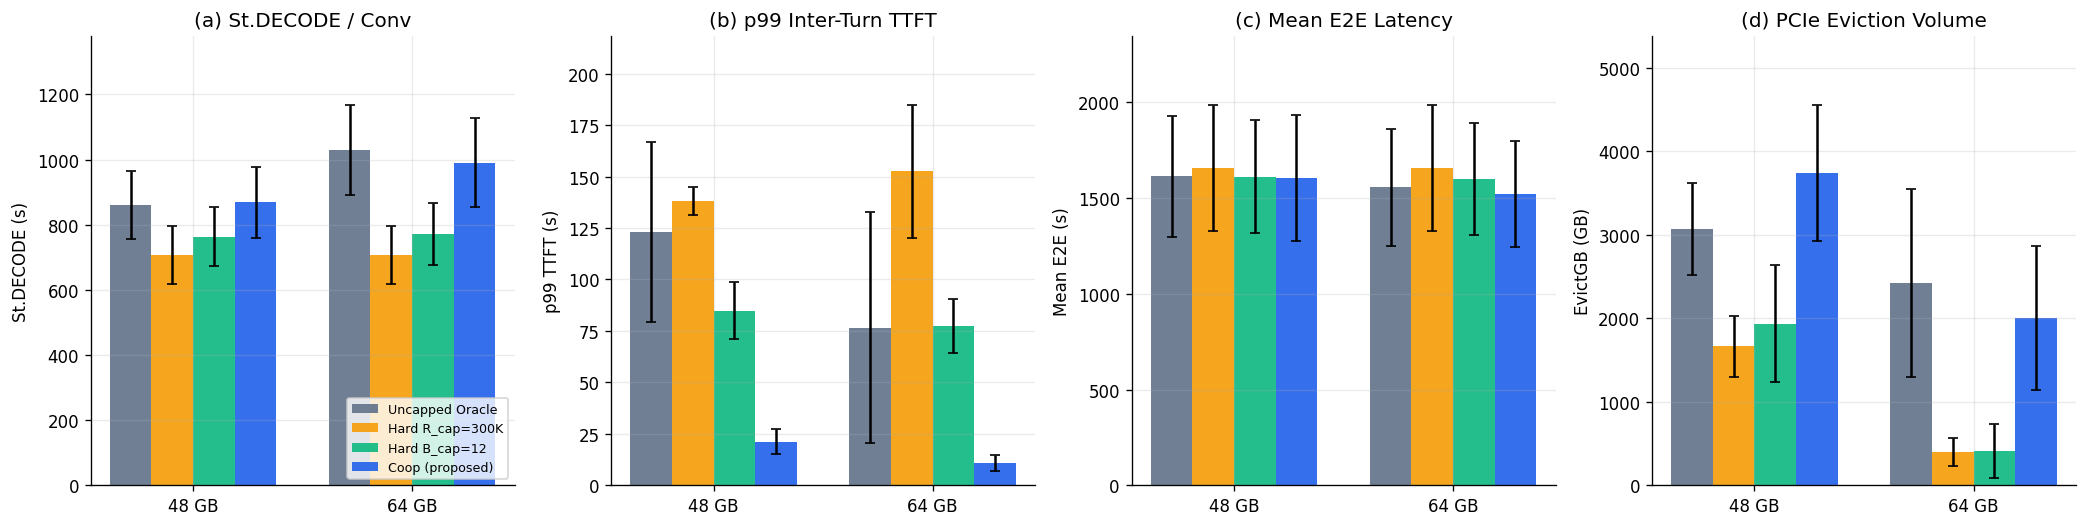

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(17.5, 4.5))
hbms = [48.0, 64.0]
x = np.arange(len(hbms))
w = 0.19
offs = [-1.5*w, -0.5*w, 0.5*w, 1.5*w]

for ax, (fn, title, ylabel) in zip(axes, [
    (lambda s: s["state_seconds"]["DECODE"] / s["total_requests"], "(a) St.DECODE / Conv", "St.DECODE (s)"),
    (lambda s: s["ttft_p99"], "(b) p99 Inter-Turn TTFT", "p99 TTFT (s)"),
    (lambda s: s["mean_e2e_s"], "(c) Mean E2E Latency", "Mean E2E (s)"),
    (lambda s: s["total_evicted_gb"], "(d) PCIe Eviction Volume", "EvictGB (GB)"),
]):
    top_v = 0.0
    for off, (lbl, _, _, col) in zip(offs, specs):
        means = [stats(h, lbl, fn)[0] for h in hbms]
        stds  = [stats(h, lbl, fn)[1] for h in hbms]
        top_v = max(top_v, max(m + sd for m, sd in zip(means, stds)))
        ax.bar(x + off, means, w, yerr=stds, capsize=3, label=lbl, color=col, alpha=0.92)
    ax.set_xticks(x); ax.set_xticklabels(["48 GB", "64 GB"])
    ax.set_title(title); ax.set_ylabel(ylabel)
    ax.set_ylim(0, top_v * 1.18)

axes[0].legend(fontsize=7.6, loc="lower right")
plt.tight_layout(); plt.show()